# Prelude

In [3]:
%cd /home/mfixman/TP/MyPyCop

/home/mfixman/Dropbox/continuous/TP/MyPyCop


In [4]:
import pandas
import scipy
import numpy
import matplotlib
import seaborn
import json
import glob

from matplotlib import pyplot

from pandas import Series, DataFrame

In [5]:
seaborn.set()

# Getting Data

In [6]:
%pwd

'/home/mfixman/Dropbox/continuous/TP/MyPyCop'

In [7]:
data = pandas.read_csv(
    'results/SAT_120s.csv',
    index_col = ['problem', 'strategy'],
)

In [8]:
strategies = data.index.get_level_values('strategy').unique()

In [9]:
strategies

Index(['FirstAction', 'LeanCopCut', 'SATSolve', 'SATSolveLiteral'], dtype='object', name='strategy')

# Analysing

In [10]:
control = ['FirstAction', 'LeanCopCut']

In [11]:
data[data.solved]

status  solved  steps  time_ms           info  \
problem    strategy                                                         
AGT001+1.p FirstAction      solved    True    4.0      3.0        Theorem   
           LeanCopCut       solved    True    4.0      3.0        Theorem   
           SATSolve         solved    True    1.0      0.0  Theorem (SAT)   
           SATSolveLiteral  solved    True    1.0      0.0  Theorem (SAT)   
AGT001+2.p FirstAction      solved    True    4.0      2.0        Theorem   
...                            ...     ...    ...      ...            ...   
SWV985-1.p SATSolveLiteral  solved    True    1.0      0.0  Theorem (SAT)   
SWW317+1.p FirstAction      solved    True   12.0     13.0        Theorem   
           LeanCopCut       solved    True   12.0     12.0        Theorem   
SWW390+1.p FirstAction      solved    True   10.0    483.0        Theorem   
           LeanCopCut       solved    True   10.0    482.0        Theorem   

                           error  
problem    strategy               
AGT001+1.p FirstAction       NaN  
           LeanCopCut        NaN  
           SATSolve          NaN  
           SATSolveLiteral   NaN  
AGT001+2.p FirstAction       NaN  
...                          ...  
SWV985-1.p SATSolveLiteral   NaN  
SWW317+1.p FirstAction       NaN  
           LeanCopCut        NaN  
SWW390+1.p FirstAction       NaN  
           LeanCopCut        NaN  

[6137 rows x 6 columns]

In [12]:
data[data.solved].groupby(level = 1).size()

strategy
FirstAction        1077
LeanCopCut         1218
SATSolve           1886
SATSolveLiteral    1956
dtype: int64

In [13]:
solved = data['solved'].unstack('strategy')

In [14]:
solved[solved.sum(axis = 1) == 1].sum(axis = 0)

strategy
FirstAction         0
LeanCopCut         15
SATSolve           47
SATSolveLiteral    96
dtype: object

# Results

<Axes: xlabel='strategy'>

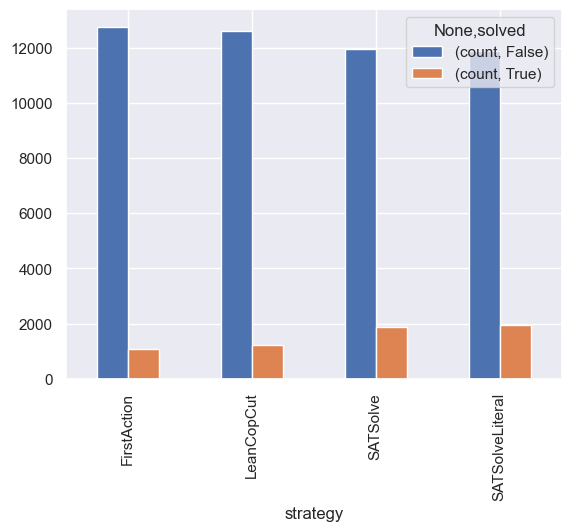

In [15]:
data.groupby(level = 'strategy').solved.value_counts().to_frame().reset_index('solved').pivot(columns = 'solved').plot.bar()

<Axes: xlabel='winner', ylabel='loser'>

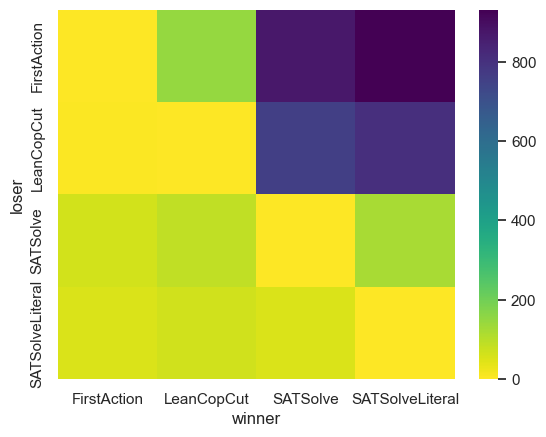

In [16]:
merged = pandas.merge(
    data.reset_index('strategy'),
    data.reset_index('strategy'),
    left_index = True,
    right_index = True,
    suffixes = ('_left', '_right'),
).set_index(['strategy_left', 'strategy_right'], append = True)

# merged = merged[merged.strategy_left < merged.strategy_right]
results = (
    merged
    [~merged.solved_left & merged.solved_right]
    .reset_index(['strategy_left', 'strategy_right'])
    [['strategy_left', 'strategy_right']]
    .value_counts()
    .unstack(level = 'strategy_right', fill_value = 0)
    .rename_axis(index = 'loser', columns = 'winner')
)

seaborn.heatmap(results, cmap = 'viridis_r')

In [17]:
tr = {}
for problem in merged.index.get_level_values('problem').unique():
    base = problem[0:3]
    a = open(f'/home/mfixman/TP/TPTP/Problems/{base}/{problem}').readlines(100000)
    tr[problem] = sum(1 for x in a if x and not x.isspace() and x[0] != '%')

tr = Series(tr, name = 'length')
tr.index.name = 'problem'

In [42]:
statistics = (
    merged
    .xs('SATSolve', level = 'strategy_right')
    # .loc[lambda x: ~x.solved_left & x.solved_right]
    .loc[lambda x: x.index.get_level_values('problem').str.contains('-')]
    # .loc[lambda x: x.index.get_level_values('strategy_left') != 'SATSolve']
    # .groupby(level = 'problem')
    # .filter(lambda x: len(x) == 3)
    .join(tr)
    .sort_values(['steps_right', 'length'], kind = 'stable')
)
statistics.loc[lambda x: (x.steps_right == 1) & (x.steps_left > 10)].sort_values('steps_left').head(40)

status_left  solved_left  steps_left  time_ms_left  \
problem    strategy_left                                                      
SWV904-1.p FirstAction        solved         True       164.0          26.0   
           LeanCopCut         solved         True       164.0          17.0   
PUZ004-1.p FirstAction        solved         True       235.0           6.0   
           LeanCopCut         solved         True       235.0           6.0   
GRA001-1.p LeanCopCut         solved         True       467.0          18.0   
           FirstAction        solved         True       534.0          22.0   
PUZ009-1.p LeanCopCut         solved         True       830.0          35.0   
PUZ033-1.p LeanCopCut         solved         True      1021.0          41.0   
PUZ009-1.p FirstAction        solved         True      1181.0          52.0   
PUZ013-1.p LeanCopCut         solved         True      1194.0          49.0   
           FirstAction        solved         True      1425.0          63.0   
PUZ033-1.p FirstAction        solved         True      1489.0          65.0   
PUZ008-2.p LeanCopCut         solved         True      2968.0        1699.0   
           FirstAction        solved         True      3321.0        2245.0   
PUZ014-1.p LeanCopCut         solved         True      7388.0         743.0   
           FirstAction        solved         True     67441.0       10719.0   

                         info_left error_left status_right  solved_right  \
problem    strategy_left                                                   
SWV904-1.p FirstAction     Theorem        NaN       solved          True   
           LeanCopCut      Theorem        NaN       solved          True   
PUZ004-1.p FirstAction     Theorem        NaN       solved          True   
           LeanCopCut      Theorem        NaN       solved          True   
GRA001-1.p LeanCopCut      Theorem        NaN       solved          True   
           FirstAction     Theorem        NaN       solved          True   
PUZ009-1.p LeanCopCut      Theorem        NaN       solved          True   
PUZ033-1.p LeanCopCut      Theorem        NaN       solved          True   
PUZ009-1.p FirstAction     Theorem        NaN       solved          True   
PUZ013-1.p LeanCopCut      Theorem        NaN       solved          True   
           FirstAction     Theorem        NaN       solved          True   
PUZ033-1.p FirstAction     Theorem        NaN       solved          True   
PUZ008-2.p LeanCopCut      Theorem        NaN       solved          True   
           FirstAction     Theorem        NaN       solved          True   
PUZ014-1.p LeanCopCut      Theorem        NaN       solved          True   
           FirstAction     Theorem        NaN       solved          True   

                          steps_right  time_ms_right     info_right  \
problem    strategy_left                                              
SWV904-1.p FirstAction            1.0            0.0  Theorem (SAT)   
           LeanCopCut             1.0            0.0  Theorem (SAT)   
PUZ004-1.p FirstAction            1.0            0.0  Theorem (SAT)   
           LeanCopCut             1.0            0.0  Theorem (SAT)   
GRA001-1.p LeanCopCut             1.0            0.0  Theorem (SAT)   
           FirstAction            1.0            0.0  Theorem (SAT)   
PUZ009-1.p LeanCopCut             1.0            0.0  Theorem (SAT)   
PUZ033-1.p LeanCopCut             1.0            0.0  Theorem (SAT)   
PUZ009-1.p FirstAction            1.0            0.0  Theorem (SAT)   
PUZ013-1.p LeanCopCut             1.0            0.0  Theorem (SAT)   
           FirstAction            1.0            0.0  Theorem (SAT)   
PUZ033-1.p FirstAction            1.0            0.0  Theorem (SAT)   
PUZ008-2.p LeanCopCut             1.0            0.0  Theorem (SAT)   
           FirstAction            1.0            0.0  Theorem (SAT)   
PUZ014-1.p LeanCopCut             1.0            0.0  Theorem (SAT)   
           FirstAction    

# 

In [ ]:
pandas.Series(tr)